# 06 — Evaluating a PSF

The previous notebook built and trained a PSF model by hand.  This one uses
the one-call path and then *measures* the result:

- `fit_psf` and `apply_psf` — fit on simulated discs, then correct a scene
- `adjeff.reference` — the atmospheric PSF of Wu et al. (2024), to compare against
- `adjeff.analysis` — encircled radius, FWHM, MTF, RMSE

**GPU required.**

Reference: [user guide §10, Analysis and the `.adjeff` accessor](../docs/guide.md#10-analysis-and-the-adjeff-accessor).

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import structlog
import xarray as xr

from adjeff.analysis import bias, encircled_energy, encircled_radius, fwhm, mtf, rmse
from adjeff.api import apply_psf, fit_psf, make_full_config, run_forward_pipeline, sample_psf_atm
from adjeff.core import KingPSF, S2Band, gaussian_image_dict, psf_kernel, psf_params
from adjeff.utils import CacheStore

assert "SMARTG_DIR_AUXDATA" in os.environ, (
    "Set SMARTG_DIR_AUXDATA to the Smart-G auxiliary data directory."
)

structlog.configure(
    processors=[structlog.processors.KeyValueRenderer(key_order=["event"])],
    logger_factory=structlog.PrintLoggerFactory(file=open("/dev/null", "w")),
)

## 6.1 — A scene, simulated forward

`run_forward_pipeline` writes the radiative terms, `rho_toa` and
`rho_unif`, and records the atmosphere and geometry it used.  `fit_psf`
reads that state back, so one scene serves both.

In [2]:
BAND = S2Band.B03
RES_KM, N = 0.5, 101
ATMOSPHERE = dict(aot=0.4, rh=50.0, h=0.0, href=2.0, sza=40.0, vza=0.0, saa=0.0, vaa=0.0)

cache = CacheStore("adjeff_cache")
config = make_full_config(bands=[BAND], **ATMOSPHERE)

scene = gaussian_image_dict(
    sigma=5.0, res_km=RES_KM, rho_min=0.05, rho_max=0.6, bands=[BAND], n=N
)
scene = run_forward_pipeline(scene, **config, cache=cache, n_ph=int(1e5))

# The pipeline leaves the state it simulated at on the scene, which is
# what `fit_psf` reads back.
print("state:", [k for k in ATMOSPHERE if k in scene[BAND].coords])
print("variables:", sorted(scene[BAND].data_vars))

state: ['aot', 'rh', 'h', 'href', 'sza', 'vza', 'saa', 'vaa']
variables: ['rho_atm', 'rho_s', 'rho_toa', 'rho_unif', 'sph_alb', 'tdif_down', 'tdif_up', 'tdir_down', 'tdir_up']


## 6.2 — Fit in one call

`fit_psf` simulates its own training discs at the scene's atmosphere, fits
the model on all of them at once, and returns the frozen tree.

In [3]:
tree_king = fit_psf(
    scene,
    bands=[BAND],
    psf_type=KingPSF,
    init_parameters={"sigma": 0.3, "gamma": 1.3},
    train_radii=[1.0, 5.0],
    n_train=N,
    res_km=RES_KM,
    cache=cache,
)

kernel_king = psf_kernel(tree_king, BAND)
fitted = psf_params(tree_king, BAND)
print({k: round(float(v.squeeze()), 4) for k, v in fitted.items()})

{'sigma': 0.0851, 'gamma': 1.052}


## 6.3 — The reference PSF

`adjeff.reference` ships the sampled atmospheric PSF of Wu et al. (2024).
It is a Monte-Carlo draw, not a fit, so it needs no training scene.

In [4]:
tree_wu = sample_psf_atm(
    bands=[BAND],
    res_km=RES_KM,
    n=N,
    atmo_config=config["atmo_config"],
    geo_config=config["geo_config"],
    cache=cache,
)
kernel_wu = psf_kernel(tree_wu, BAND).squeeze()
print("Wu kernel dims:", dict(kernel_wu.sizes))

Wu kernel dims: {'y_psf': 101, 'x_psf': 101}


## 6.4 — Compare the two kernels

`adjeff.analysis` reduces a kernel to numbers: the radius holding a given
share of its energy, its full width at half maximum, and its transfer
function.

In [5]:
rows = []
for name, kernel in (("King", kernel_king.squeeze()), ("Wu 2024", kernel_wu)):
    rows.append(
        (name,
         encircled_radius(kernel, 0.5),
         encircled_radius(kernel, 0.9),
         fwhm(kernel))
    )

print(f"{'model':10s} {'r50 [km]':>9} {'r90 [km]':>9} {'FWHM [km]':>10}")
for name, r50, r90, w in rows:
    print(f"{name:10s} {r50:>9.3f} {r90:>9.3f} {w:>10.3f}")

model       r50 [km]  r90 [km]  FWHM [km]
King           0.941    15.161      0.832
Wu 2024        1.192     7.116      1.219


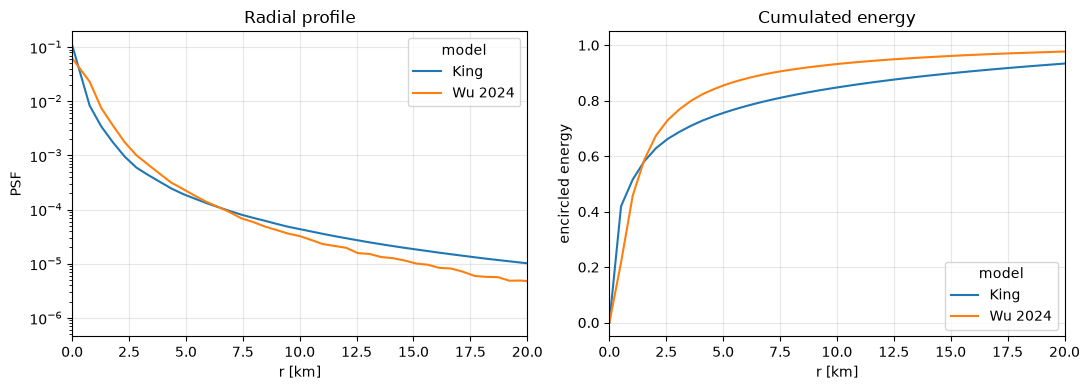

In [6]:
# Both kernels on one axis each: a reduction keeps the dimensions it
# does not read, so `hue=` is all the loop ever was.
kernels = xr.concat(
    [kernel_king.squeeze(drop=True), kernel_wu],
    dim=xr.DataArray(["King", "Wu 2024"], dims=["model"], name="model"),
)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
kernels.adjeff.radial().plot(hue="model", ax=ax1)
encircled_energy(kernels).plot(hue="model", ax=ax2)

ax1.set(xlabel="r [km]", ylabel="PSF", yscale="log", xlim=(0, 20),
        title="Radial profile")
ax2.set(xlabel="r [km]", ylabel="encircled energy", xlim=(0, 20),
        title="Cumulated energy")
for ax in (ax1, ax2):
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 6.5 — Apply it, and measure what it recovers

`apply_psf` runs the correction with a frozen tree, writing its estimate
to `rho_s_est` so the truth the scene was built from stays put.  The
baseline is `rho_unif`, what a correction that ignores adjacency
leaves.

In [7]:
# `Unif2Surface` writes its estimate into `rho_s`, so keep the truth first.
truth = scene[BAND]["rho_s"].squeeze(drop=True)

corrected = apply_psf(scene, tree_king, BAND, psf_type=KingPSF)
estimate = corrected[BAND]["rho_s_est"].squeeze(drop=True)
uncorrected = scene[BAND]["rho_unif"].squeeze(drop=True)

print(f"{'':16s} {'RMSE':>10} {'bias':>10}")
for label, field in (("no correction", uncorrected), ("King PSF", estimate)):
    print(f"{label:16s} {rmse(field, truth, mask=20.0):>10.5f} "
          f"{bias(field, truth, mask=20.0):>10.5f}")

                       RMSE       bias
no correction       0.01736   -0.00233
King PSF            0.00357   -0.00023
